<a href="https://colab.research.google.com/github/Chimix001/AGRITECH/blob/main/final_crop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.20.0


In [2]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3
EPOCHS = 50  # EarlyStopping will halt before this if needed

In [4]:
datasets = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/drive/MyDrive/Tomato",
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 2543 files belonging to 2 classes.


In [5]:
class_names = datasets.class_names
print('Classes found:', class_names)
print('Total batches:', len(datasets))

Classes found: ['Tomato_Leaf_Mold', 'Tomato_healthy']
Total batches: 80


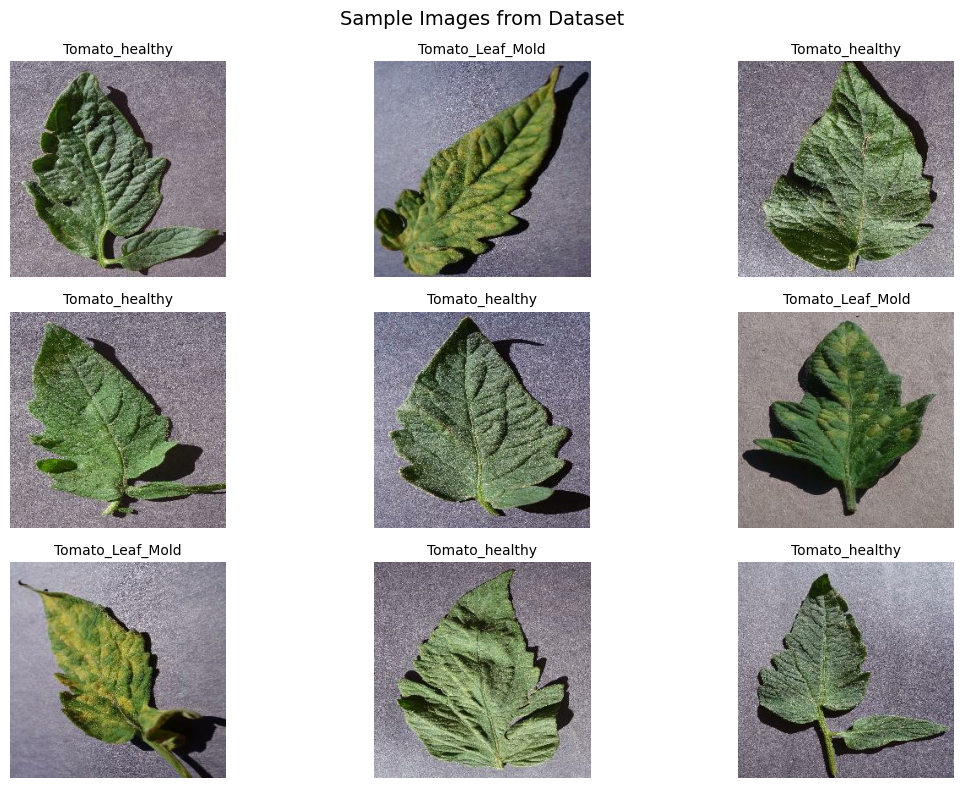

In [6]:
plt.figure(figsize=(12, 8))
for image_batch, label_batch in datasets.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(image_batch[i].numpy().astype('uint8'))
        plt.title(class_names[label_batch[i]], fontsize=10)
        plt.axis('off')
plt.suptitle('Sample Images from Dataset', fontsize=14)
plt.tight_layout()
plt.show()

Class image counts:
  Tomato_Leaf_Mold: 952 images
  Tomato_healthy: 1591 images


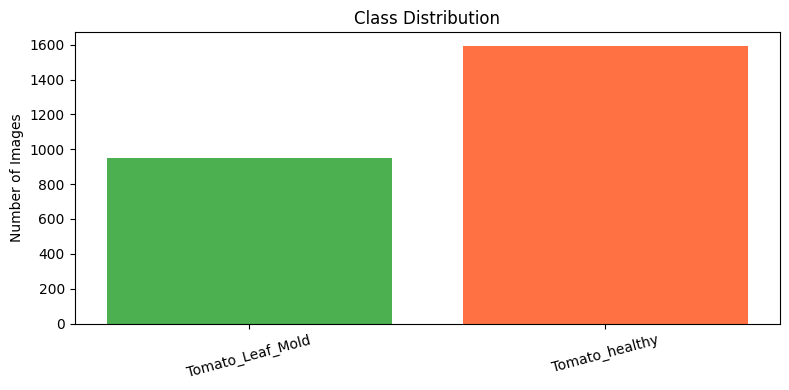

In [7]:
all_labels = []
for _, label_batch in datasets:
    all_labels.extend(label_batch.numpy())

label_counts = Counter(all_labels)
print('Class image counts:')
for idx, name in enumerate(class_names):
    print(f'  {name}: {label_counts[idx]} images')

# Bar chart
plt.figure(figsize=(8, 4))
plt.bar([class_names[k] for k in sorted(label_counts)],
        [label_counts[k] for k in sorted(label_counts)],
        color=['#4CAF50', '#FF7043', '#42A5F5'][:len(class_names)])
plt.title('Class Distribution')
plt.ylabel('Number of Images')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [8]:
total_images = sum(label_counts.values())
n_classes = len(class_names)

# Inverse frequency weighting: rarer class gets higher weight
class_weights = {
    k: total_images / (n_classes * v)
    for k, v in label_counts.items()
}

print('Class weights (higher = model penalised more for missing that class):')
for idx, name in enumerate(class_names):
    print(f'  {name}: {class_weights[idx]:.4f}')

Class weights (higher = model penalised more for missing that class):
  Tomato_Leaf_Mold: 1.3356
  Tomato_healthy: 0.7992


In [9]:
def get_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1,
                       shuffle=True, shuffle_size=10000):
    assert (train_split + val_split + test_split) == 1
    ds_size = len(ds)
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=42)
    train_size = int(train_split * ds_size)
    val_size   = int(val_split   * ds_size)
    train_ds = ds.take(train_size)
    val_ds   = ds.skip(train_size).take(val_size)
    test_ds  = ds.skip(train_size).skip(val_size)
    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = get_partitions_tf(datasets)
print(f'Train batches : {len(train_ds)}')
print(f'Val batches   : {len(val_ds)}')
print(f'Test batches  : {len(test_ds)}')

Train batches : 64
Val batches   : 8
Test batches  : 8


In [10]:
train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds   = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [11]:
# Resize + normalise (applied to ALL splits)
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0 / 255)
], name='resize_rescale')

# Augmentation — placed INSIDE the model so it only fires during model.fit()
# This means val/test images are NEVER augmented (correct behaviour)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augmentation')

print('Preprocessing and augmentation layers ready.')

Preprocessing and augmentation layers ready.


In [12]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = len(class_names)

model = models.Sequential([
    resize_and_rescale,           # normalise pixel values
    data_augmentation,            # augment ONLY during training

    layers.Conv2D(32,  (3, 3), activation='relu', input_shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,  (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,  (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),          # randomly zeros 40% of neurons — prevents memorisation

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(n_classes, activation='softmax'),
], name='tomato_disease_cnn')

model.build(input_shape=input_shape)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "tomato_disease_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resize_rescale (Sequential)     │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 28, 28, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 14, 14, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 12, 12, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 6, 6, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 4608)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 128)              │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (32, 128)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 64)               │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (32, 64)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (32, 2)                │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 876,098 (3.34 MB)

 Trainable params: 876,098 (3.34 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [14]:
callbacks = [
    # Stop training when val_loss stops improving
    EarlyStopping(
        monitor='val_loss',
        patience=7,                  # wait 7 epochs before stopping
        restore_best_weights=True,   # roll back to the best checkpoint automatically
        verbose=1
    ),
    # Reduce learning rate when stuck
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,                  # halve the LR
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print('Callbacks configured.')

Callbacks configured.


In [15]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,    # penalise missing the minority class (Leaf Mold) more
    verbose=1
)

Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 369s 5s/step - accuracy: 0.5151 - loss: 0.6961 - val_accuracy: 0.5977 - val_loss: 0.6173 - learning_rate: 0.0010
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 335s 5s/step - accuracy: 0.6509 - loss: 0.5948 - val_accuracy: 0.8008 - val_loss: 0.5123 - learning_rate: 0.0010
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 330s 5s/step - accuracy: 0.9272 - loss: 0.2149 - val_accuracy: 0.8945 - val_loss: 0.4827 - learning_rate: 0.0010
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 327s 5s/step - accuracy: 0.9453 - loss: 0.1506 - val_accuracy: 0.9141 - val_loss: 0.4240 - learning_rate: 0.0010
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 376s 5s/step - accuracy: 0.9697 - loss: 0.0847 - val_accuracy: 0.9570 - val_loss: 0.2323 - learning_rate: 0.0010
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 322s 5s/step - accuracy: 0.9819 - loss: 0.0529 - val_accuracy: 0.8945 - val_loss: 1.0400 - learning_rate: 0.0010
Epoch 7/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 320s 5s/step - accuracy: 0.9722 - loss: 0.0879 - val_acc

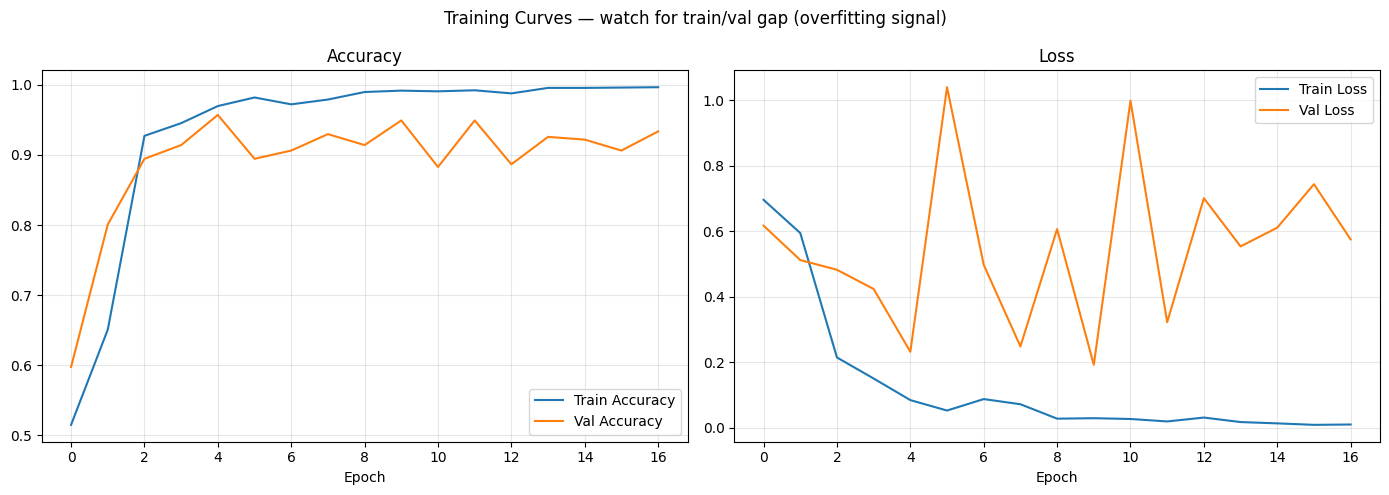

Training stopped at epoch 17 (best weights restored)


In [16]:
actual_epochs = len(history.history['loss'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(range(actual_epochs), history.history['accuracy'],     label='Train Accuracy')
axes[0].plot(range(actual_epochs), history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(range(actual_epochs), history.history['loss'],     label='Train Loss')
axes[1].plot(range(actual_epochs), history.history['val_loss'], label='Val Loss')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Training Curves — watch for train/val gap (overfitting signal)', fontsize=12)
plt.tight_layout()
plt.show()

print(f'Training stopped at epoch {actual_epochs} (best weights restored)')

In [17]:
scores = model.evaluate(test_ds, verbose=1)
print(f'\nTest Loss    : {scores[0]:.4f}')
print(f'Test Accuracy: {scores[1]*100:.2f}%')

8/8 ━━━━━━━━━━━━━━━━━━━━ 25s 982ms/step - accuracy: 0.9623 - loss: 0.1444

Test Loss    : 0.1444
Test Accuracy: 96.23%


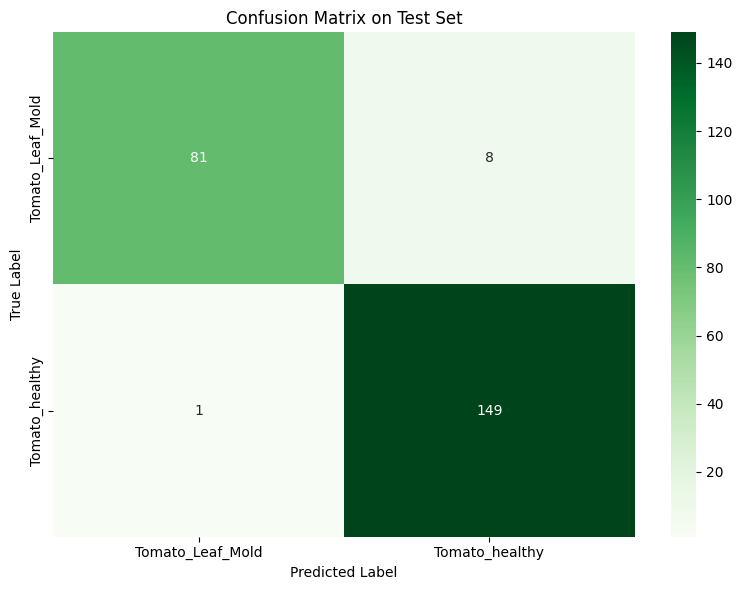


Classification Report:
                  precision    recall  f1-score   support

Tomato_Leaf_Mold       0.99      0.91      0.95        89
  Tomato_healthy       0.95      0.99      0.97       150

        accuracy                           0.96       239
       macro avg       0.97      0.95      0.96       239
    weighted avg       0.96      0.96      0.96       239



In [18]:
y_true = []
y_pred = []

for image_batch, label_batch in test_ds:
    preds = model.predict(image_batch, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(label_batch.numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Test Set')
plt.tight_layout()
plt.show()

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=class_names))

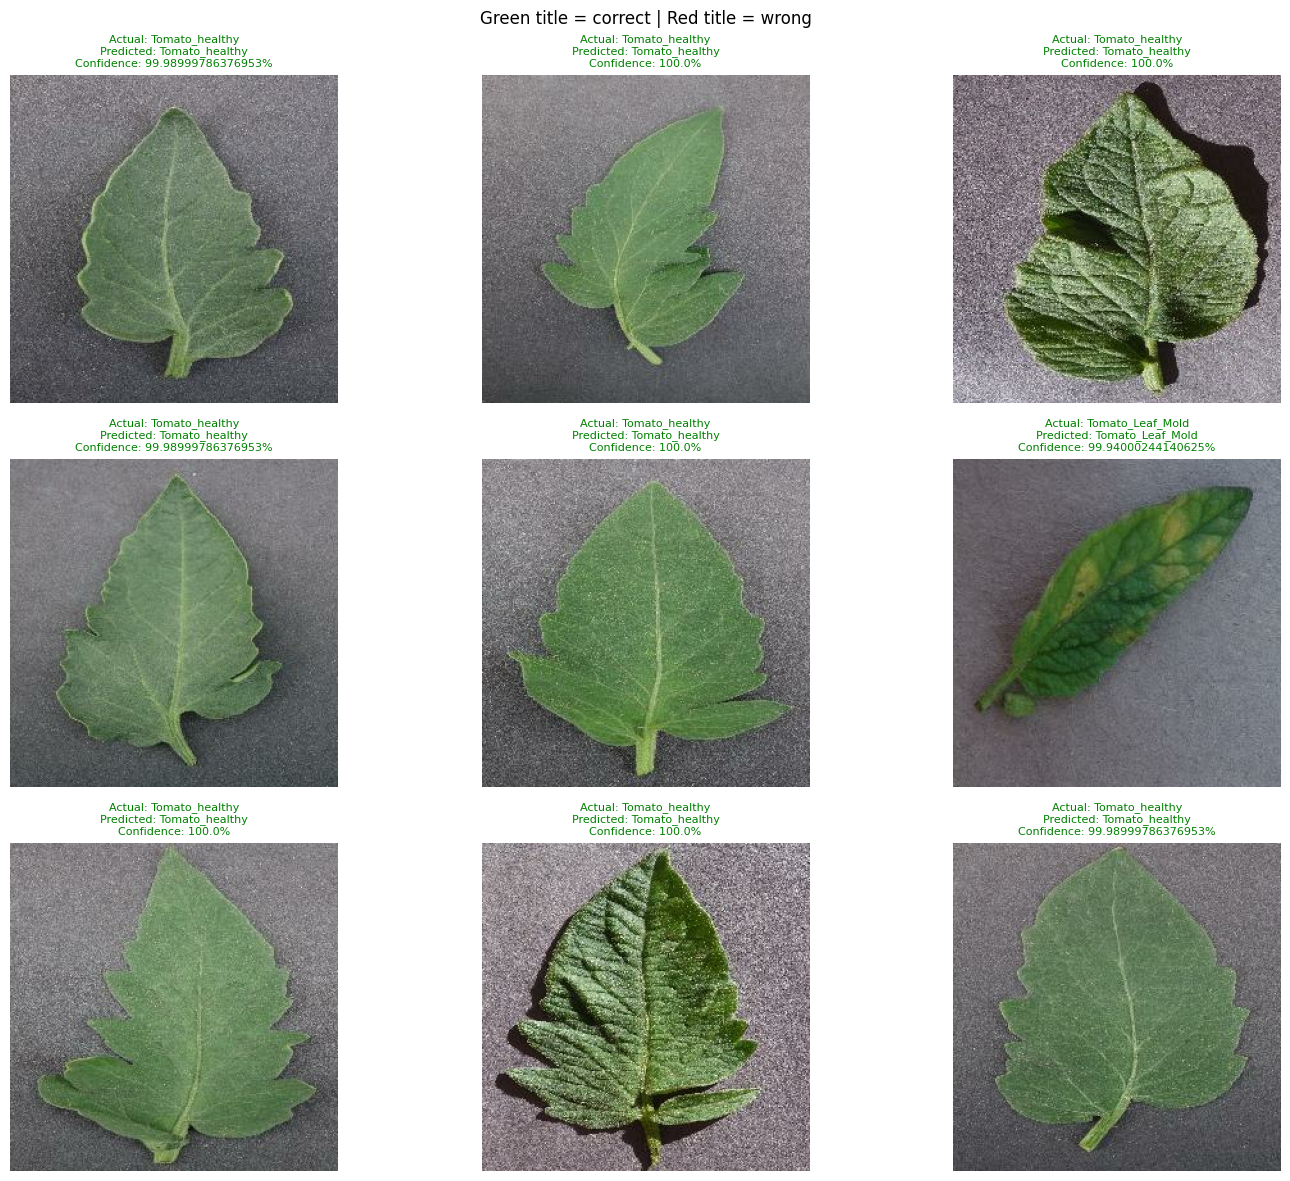

In [19]:
def predict(model, img_array):
    """Predict class and confidence for a single image array (H, W, C)."""
    inp = tf.expand_dims(img_array, axis=0)  # add batch dimension
    predictions = model.predict(inp, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * np.max(predictions[0]), 2)
    return predicted_class, confidence

plt.figure(figsize=(15, 12))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        img = images[i].numpy().astype('uint8')
        plt.imshow(img)

        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]
        correct = predicted_class == actual_class

        color = 'green' if correct else 'red'
        plt.title(
            f'Actual: {actual_class}\nPredicted: {predicted_class}\nConfidence: {confidence}%',
            color=color, fontsize=8
        )
        plt.axis('off')

plt.suptitle('Green title = correct | Red title = wrong', fontsize=12)
plt.tight_layout()
plt.show()

In [20]:
import os

save_dir = '/content/drive/MyDrive/models'
os.makedirs(save_dir, exist_ok=True)

existing = [int(i) for i in os.listdir(save_dir) if i.isdigit()]
model_version = max(existing + [0]) + 1

save_path = f'{save_dir}/{model_version}.keras'
model.save(save_path)
print(f'Model saved → {save_path}')

# Also save as .h5 for compatibility
model.save('/content/drive/MyDrive/Tomatoes_v2.h5')
print('Also saved as Tomatoes_v2.h5')

Model saved → /content/drive/MyDrive/models/1.keras
Also saved as Tomatoes_v2.h5
